# Financial Transaction Data Processing and ML-Based Anomaly Detection

Educational prototype using public UCI Online Retail data (ID 352). The original starting notebook is preserved in `project_original.ipynb`. The identifiers omitted by `ucimlrepo.data.features` are loaded here from the full local source.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_loader import find_raw_data, load_transactions
from src.feature_engineering import invoice_features
raw_path = find_raw_data(ROOT)
df = load_transactions(raw_path)
print('Source:', raw_path.name, 'Shape:', df.shape)

Source: online_retail_mirror.parquet Shape: (541909, 8)


## Raw data exploration

The next cell reports the actual dimensions, types, first and last records, missingness, duplicates, distributions, date range, invoices, customers, countries, negative quantities, and cancellation markers. Extreme values are reported without deleting them.

In [2]:
display(df.head(), df.tail())
print('Types:')
print(df.dtypes)
print('Missing by column:')
print(df.isna().sum())
print('Exact duplicates:', df.duplicated().sum())
print('Numeric summary:')
display(df[['Quantity', 'UnitPrice']].describe())
dates = pd.to_datetime(df.InvoiceDate, errors='coerce')
print('Date range:', dates.min(), dates.max())
print('Invoices:', df.InvoiceNo.nunique(), 'Customers:', df.CustomerID.nunique())
print('Negative quantities:', (df.Quantity < 0).sum())
print('Cancelled invoice rows:', df.InvoiceNo.astype('string').str.match(r'^[Cc]\d{6}$', na=False).sum())
print('Top countries:')
display(df.Country.value_counts().head(15))
print('Customer line count summary:')
display(df.groupby('CustomerID', dropna=True).size().describe())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00.000000000,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00.000000000,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00.000000000,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00.000000000,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00.000000000,3.39,17850.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00.000000000,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00.000000000,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00.000000000,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00.000000000,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00.000000000,4.95,12680.0,France


Types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float32
CustomerID     float32
Country            str
dtype: object
Missing by column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Exact duplicates: 5268
Numeric summary:


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759850
min,-80995.000000,-11062.059570
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


Date range: 2010-12-01 08:26:00 2011-12-09 12:50:00
Invoices: 25900 Customers: 4372
Negative quantities: 10624
Cancelled invoice rows: 9288
Top countries:


Country
United Kingdom     495478
Germany              9495
France               8557
EIRE                 8196
Spain                2533
Netherlands          2371
Belgium              2069
Switzerland          2002
Portugal             1519
Australia            1259
Norway               1086
Italy                 803
Channel Islands       758
Finland               695
Cyprus                622
Name: count, dtype: int64

Customer line count summary:


count    4372.000000
mean       93.053294
std       232.471608
min         1.000000
25%        17.000000
50%        42.000000
75%       102.000000
max      7983.000000
dtype: float64

## Observed data quality findings

The executed pipeline found **541,909** source lines, **5,268** exact duplicates, and **3** invalid lines excluding duplicates. It retained **536,638** lines: **526,051** sales and **10,587** returns/cancellations. **5,367** retained lines received review flags. Missing values before cleaning: `{'InvoiceNo': 0, 'StockCode': 0, 'Description': 1454, 'Quantity': 0, 'InvoiceDate': 0, 'UnitPrice': 0, 'CustomerID': 135080, 'Country': 0}`. These figures come from the executed pipeline output.

In [3]:
cleaned = pd.read_parquet(ROOT / 'data/processed/transactions_audit.parquet')
print('Audit categories:')
display(cleaned.category.value_counts())
print('Review examples:')
display(cleaned.loc[cleaned.review_flag, ['source_row_id','InvoiceNo','Quantity','UnitPrice','amount_gbp','category']].head(10))
print('Invalid reasons:')
display(cleaned.loc[cleaned.category.eq('invalid'), 'invalid_reason'].value_counts().head(10))

Audit categories:


category
sale                      526051
return_or_cancellation     10587
duplicate                   5268
invalid                        3
Name: count, dtype: int64

Review examples:


,source_row_id,InvoiceNo,Quantity,UnitPrice,amount_gbp,category
65,65,536374,32,10.95,350.399994,sale
178,178,536387,192,3.82,733.439987,sale
179,179,536387,192,3.37,647.039978,sale
180,180,536387,192,3.37,647.039978,sale
181,181,536387,432,1.45,626.400021,sale
182,182,536387,432,1.25,540.000000,sale
415,415,536405,128,2.55,326.399994,sale
622,622,536414,56,0.00,0.000000,sale
870,870,536477,480,3.39,1627.200050,sale
1576,1576,536544,40,12.72,508.800011,sale


Invalid reasons:


invalid_reason
invoice_id;unit_price_negative;    2
invoice_id;                        1
Name: count, dtype: int64

## Cleaning decisions and invoice consistency

Raw rows remain untouched. Exact duplicate exclusion is an assumption because identical lines could be genuine repeated items. Missing CustomerID is accepted; a supplied malformed ID is audited and its invoice withheld from ML. Nonfinite quantity, price, or amount is invalid. Returns remain a separate category. Of 20,725 sale invoices, 42 have multiple line times; variation within 24 hours is allowed. Conflicting known customers/countries or a span beyond 24 hours is flagged, and 0 invoices are excluded. Assuming complete invoices, the latest line time is the model date.

In [4]:
invoices = pd.read_parquet(ROOT / 'data/processed/invoice_quality.parquet')
scored = pd.read_parquet(ROOT / 'data/processed/invoice_predictions.parquet')
print('Sale invoices:', len(invoices), 'Eligible:', invoices.eligible_for_model.sum())
print('Invoice conflict reasons:')
display(invoices.invoice_conflict_reason.value_counts().head(10))
print('Model flags by subset:')
display(scored.groupby('subset').is_anomaly.agg(['sum','count']))
print('Holdout model/rule comparison:')
display(scored.loc[scored.subset.eq('holdout')].groupby(['is_anomaly','rule_flag']).size())
print('Highest anomaly scores:')
display(scored.sort_values('anomaly_score', ascending=False)[['InvoiceNo','invoice_date','country','total_gbp','line_count','anomaly_score','is_anomaly']].head(10))

Sale invoices: 20725 Eligible: 20725
Invoice conflict reasons:


invoice_conflict_reason
    20725
Name: count, dtype: int64

Model flags by subset:


,sum,count
subset,,
holdout,119,4144
train,332,16581


Holdout model/rule comparison:


is_anomaly  rule_flag
False       False        3997
            True           28
True        False          55
            True           64
dtype: int64

Highest anomaly scores:


,InvoiceNo,invoice_date,country,total_gbp,line_count,anomaly_score,is_anomaly
16985,573585,2011-10-31 14:41:00,United Kingdom,16874.580024,1114,0.090116,True
20326,580729,2011-12-05 17:24:00,United Kingdom,9020.829971,721,0.088260,True
449,537237,2010-12-06 09:58:00,United Kingdom,7335.449957,597,0.086711,True
1016,538524,2010-12-13 09:35:00,United Kingdom,5344.979957,490,0.082144,True
20327,580730,2011-12-05 17:28:00,United Kingdom,6870.199981,662,0.081860,True
452,537240,2010-12-06 10:08:00,United Kingdom,7660.479951,568,0.081735,True
1877,540551,2011-01-10 09:43:00,United Kingdom,4731.639980,502,0.081426,True
12033,562955,2011-08-11 10:14:00,United Kingdom,16677.260002,353,0.079666,True
20563,581219,2011-12-08 09:28:00,United Kingdom,8159.030017,749,0.077900,True
539,537434,2010-12-06 16:57:00,United Kingdom,8223.399964,675,0.077456,True


## Model assessment

Training: **16,581** invoices through **2011-10-26 12:28:00**. Holdout: **4,144** invoices from **2011-10-26 12:31:00**. Identical timestamps stay in one subset. Preprocessing is fitted on train only. On holdout, the Isolation Forest flags **119** invoices, the training-derived amount rule flags **92**, and **64** overlap. At contamination thresholds 1%, 2%, and 5%, the same forest flags **71**, **119**, and **193** holdout invoices. There are no verified anomaly labels, so precision, recall, F1, and fraud accuracy are unavailable.

## Duplicate sensitivity

Keeping 5,268 otherwise valid duplicate lines changes sale total from **£10,631,048.69** to **£10,655,622.43**. With the trained model held fixed, flagged invoices change from **451** to **451**; flags only in the alternate input: **0**. This tests input sensitivity, not confirmed detection quality.

## Figures

The figures were generated by the executed pipeline and saved under `reports/figures/`. Clipping in two raw distributions is only for display; validation and modeling use original values.

quantity.png


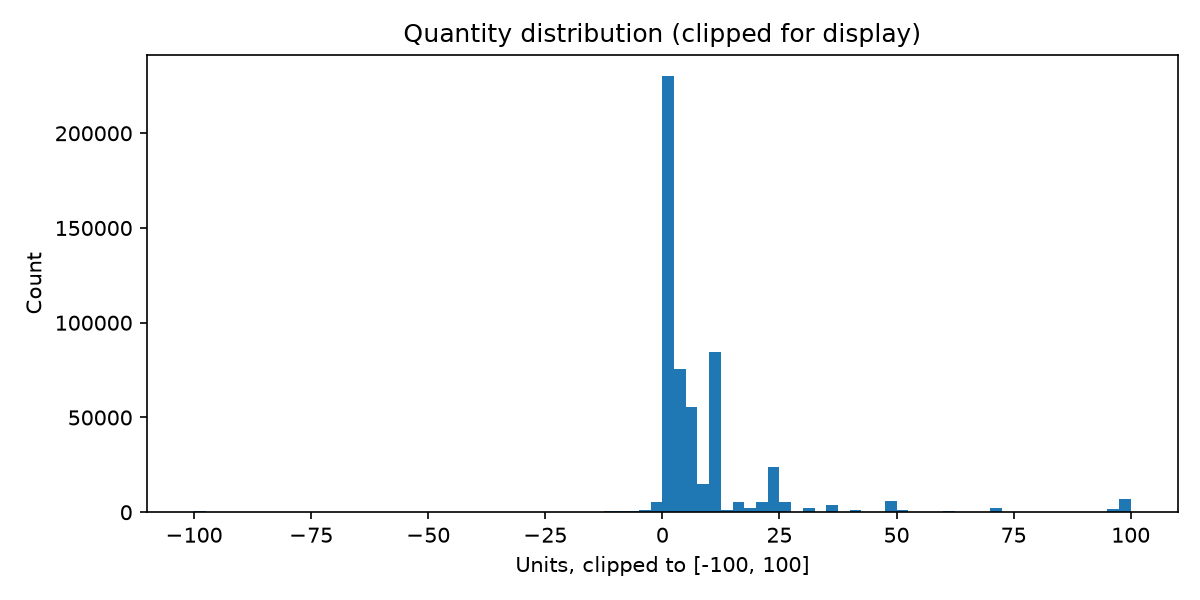

unit_price.png


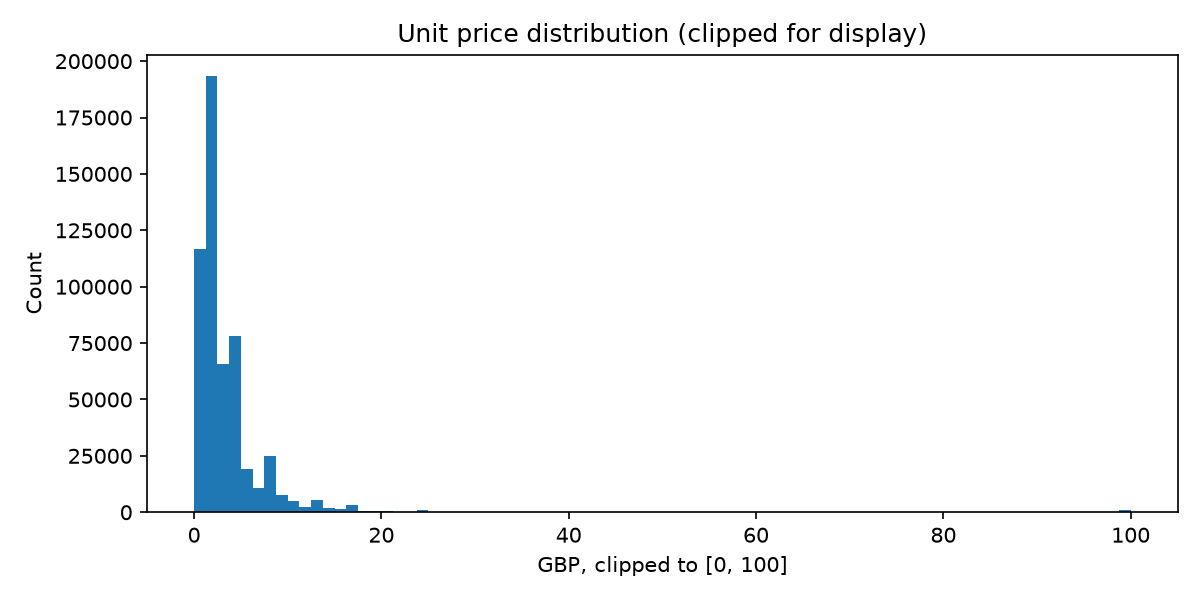

countries.png


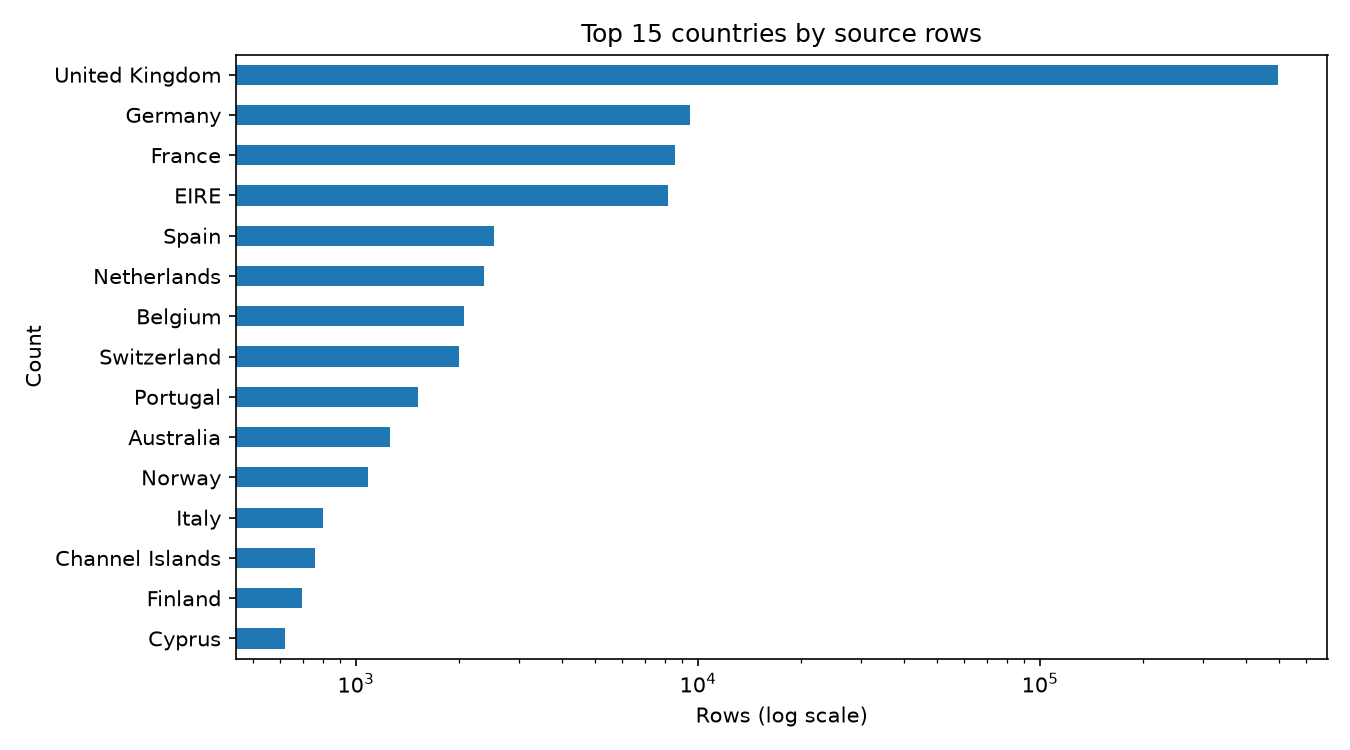

sale_amount_log.png


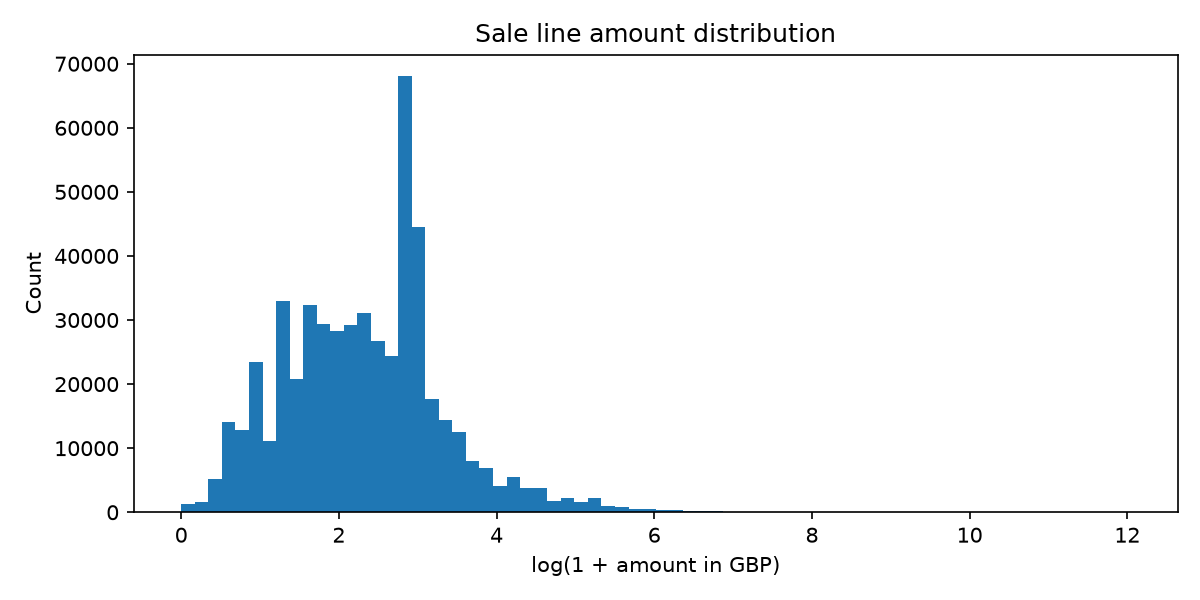

anomaly_scores.png


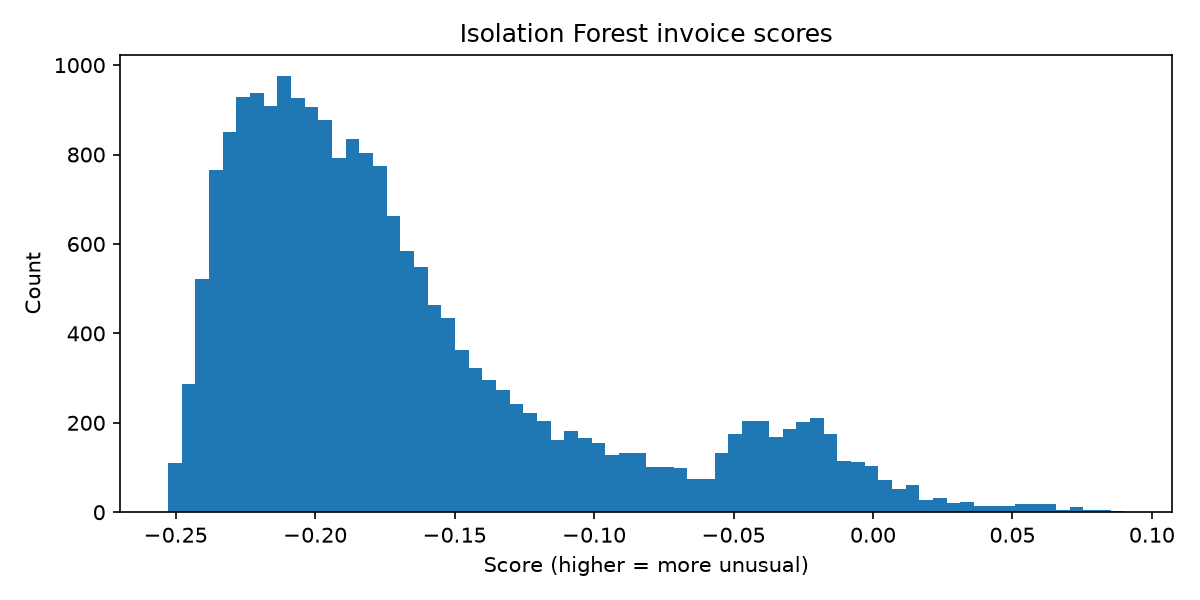

invoice_amount_comparison.png


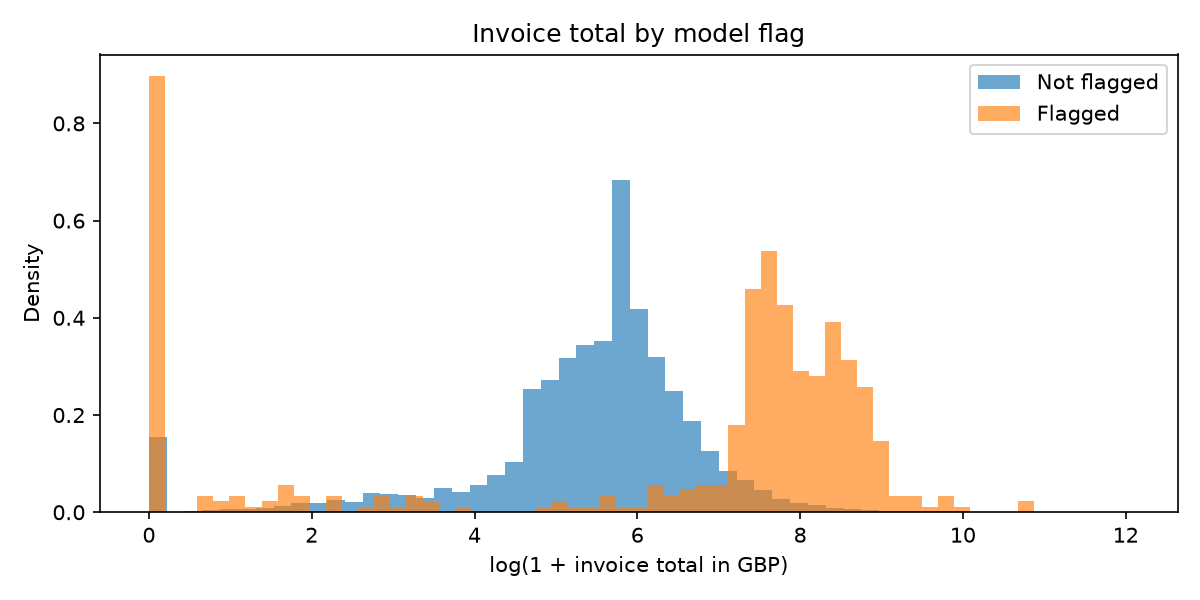

anomalies_by_country.png


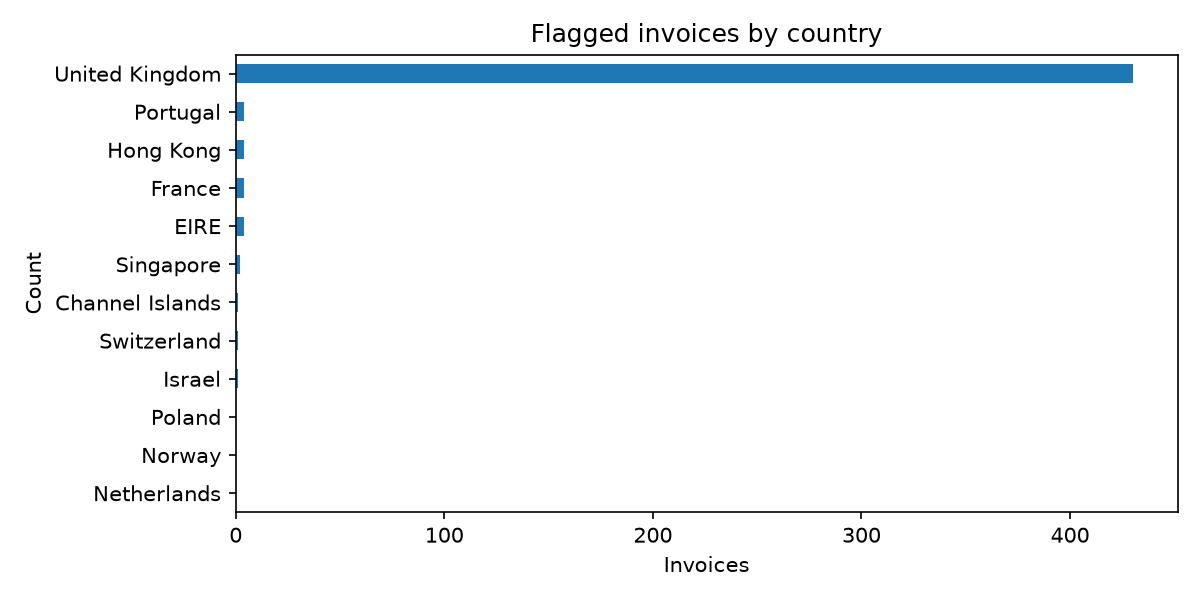

line_count_comparison.png


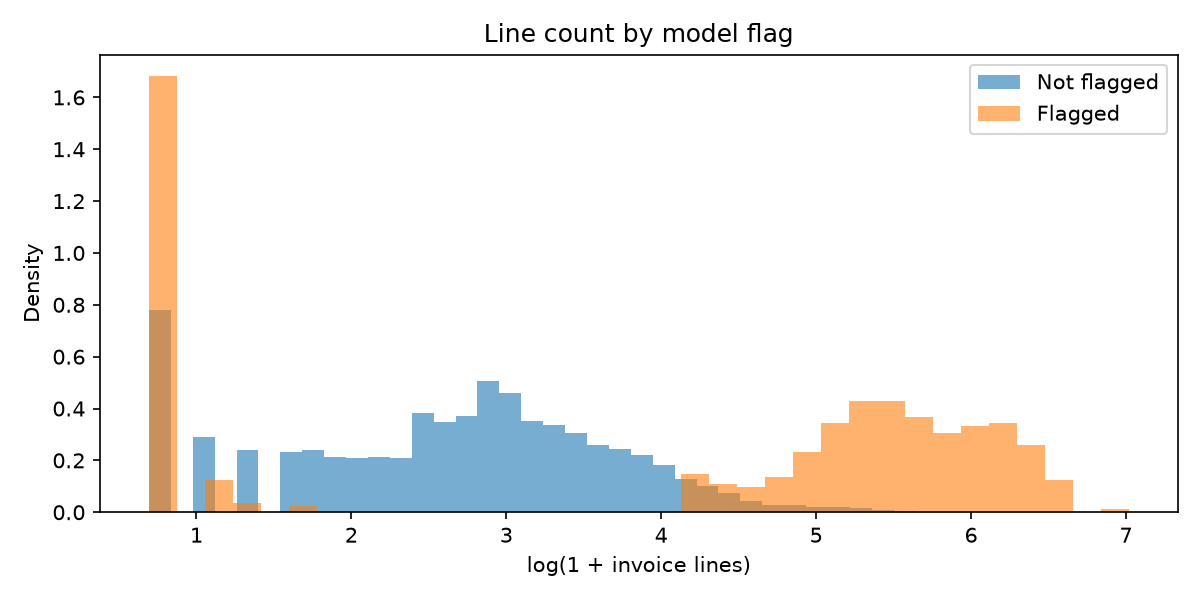

In [5]:
for name in ['quantity.png','unit_price.png','countries.png','sale_amount_log.png','anomaly_scores.png','invoice_amount_comparison.png','anomalies_by_country.png','line_count_comparison.png']:
    print(name)
    display(Image(filename=str(ROOT / 'reports/figures' / name), width=650))

## Storage, provenance, and limits

Database loading is atomic. The local run verifies SQLite row counts; PostgreSQL requires a configured test server. The reproducibility manifest records raw SHA-256, Python and package versions, model settings, and the strict time boundary. Top-scoring invoice characteristics are not confirmed explanations or evidence of fraud. The public UK retail data is not representative of ARQA BUH operations or Kazakhstan accounting workflows.

In [6]:
summary = json.loads((ROOT / 'data/processed/run_summary.json').read_text())
manifest = json.loads((ROOT / 'data/processed/reproducibility_manifest.json').read_text())
print('Database:', summary['database'])
print('Source SHA-256:', manifest['source_sha256'])
print('Python:', manifest['python_version'])
print('Kernel executable:', sys.executable)

Database: {'database_url_kind': 'sqlite', 'stored_transactions': 541909, 'stored_sale_invoices': 20725, 'stored_predictions': 20725}
Source SHA-256: 0663e4d42cda4401cd76ee44bb278f3b23f02f576399925d4701a6cf07a9591c
Python: 3.14.7
Kernel executable: /Users/daamniyar/dataset/.venv/bin/python
